In [1]:
import requests
import zipfile
import os
import gc
from tqdm import tqdm

def download_and_extract(url, extract_dir, delete_zip=True):
    zip_path = f"{extract_dir}.zip"

    os.makedirs(extract_dir, exist_ok=True)

    # 1. Download directly to disk
    with requests.get(url, stream=True) as response:
        response.raise_for_status()

        total_size = int(response.headers.get("content-length", 0))

        with open(zip_path, "wb") as f:
            with tqdm(
                total=total_size,
                unit="B",
                unit_scale=True,
                desc=f"Downloading {extract_dir}"
            ) as pbar:
                for chunk in response.iter_content(chunk_size=1024 * 1024):
                    if chunk:
                        f.write(chunk)
                        pbar.update(len(chunk))

    # 2. Extract with progress bar
    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        files = zip_ref.infolist()

        total_size = sum(file.file_size for file in files)

        with tqdm(
            total=total_size,
            unit="B",
            unit_scale=True,
            desc=f"Extracting {extract_dir}"
        ) as pbar:
            for member in files:
                if member.is_dir():
                    os.makedirs(
                        os.path.join(extract_dir, member.filename),
                        exist_ok=True
                    )
                    continue

                output_path = os.path.join(extract_dir, member.filename)
                os.makedirs(os.path.dirname(output_path), exist_ok=True)

                with zip_ref.open(member) as source, open(output_path, "wb") as target:
                    while chunk := source.read(1024 * 1024):
                        target.write(chunk)
                        pbar.update(len(chunk))

    # 3. Delete ZIP to save disk space
    if delete_zip:
        os.remove(zip_path)

    gc.collect()

    print(f"Completed: {extract_dir}")

In [3]:
!ls

audio  csv  dl_indie.ipynb  images


In [1]:
"""Reusable helpers to train, evaluate and visualize PyTorch classification models.

The helpers expect a model that outputs raw class scores (logits) and data loaders
that yield `(inputs, targets)` batches with integer class labels as targets. Batches
are moved to the device the model is on.
"""

import copy
import gc
import matplotlib.pyplot as plt
import torch
from matplotlib.ticker import MaxNLocator


def evaluate(model, loader, loss_fn):
    """Computes the mean loss and accuracy of a model.

    Args:
        model   : Classification model that outputs logits
        loader  : DataLoader yielding (inputs, targets) batches
        loss_fn : Loss function taking (logits, targets), averaged over the batch

    Returns:
        Tuple (loss, accuracy) averaged over all samples of the loader
    """
    device = next(model.parameters()).device
    model.eval()
    total_loss, correct = 0.0, 0

    with torch.no_grad():
        for X, y in loader:
            X, y = X.to(device), y.to(device)
            logits = model(X)
            total_loss += loss_fn(logits, y).item() * len(X)
            correct += (logits.argmax(dim=1) == y).sum().item()

    return total_loss / len(loader.dataset), correct / len(loader.dataset)


def fit(model, train_loader, optimizer, loss_fn, epochs, val_loader=None,
        log_every=15, scheduler=None, patience=None):
    """Trains a classification model and records its losses and accuracies.

    Args:
        model        : Classification model that outputs logits
        train_loader : DataLoader yielding (inputs, targets) training batches
        optimizer    : Optimizer over the parameters of the model
        loss_fn      : Loss function taking (logits, targets), averaged over the batch
        epochs       : Number of passes through the training data
        val_loader   : Optional DataLoader with validation data, evaluated after every epoch
        log_every    : Record the running training loss and accuracy every this many weight updates
        scheduler    : Optional learning rate scheduler, stepped at the end of every epoch.
                       ReduceLROnPlateau is stepped with the validation loss (or the training loss
                       when there is no validation data).
        patience     : Optional early stopping. Training stops when the validation loss has not
                       improved for this many epochs, and the weights with the lowest validation loss
                       are restored. Requires validation data.

    Returns:
        History dictionary of lists. 'step', 'batch_loss' and 'batch_accuracy' are recorded
        every `log_every` weight updates (the running averages over the current epoch);
        'loss', 'accuracy', 'learning_rate' and, with validation data, 'val_loss' and
        'val_accuracy' are recorded once per epoch.
    """
    
    device = next(model.parameters()).device
    model.eval()
    total_loss, correct = 0.0, 0

    if patience is not None and val_loader is None:
        raise ValueError('Early stopping (patience) requires validation data (val_loader)')

    device = next(model.parameters()).device
    keys = ['step', 'batch_loss', 'batch_accuracy', 'loss', 'accuracy', 'learning_rate']
    if val_loader is not None:
        keys += ['val_loss', 'val_accuracy']
    history = {key: [] for key in keys}
    step = 0
    best_loss, best_weights, epochs_without_improvement = float('inf'), None, 0

    for epoch in range(epochs):
        model.train()
        running_loss, running_correct, seen = 0.0, 0, 0

        pbar = tqdm(train_loader, desc=f'Epoch {epoch + 1}/{epochs}', leave=True)

        for X, y in pbar:
            X, y = X.to(device), y.to(device)

            # Forward pass
            logits = model(X)
            loss = loss_fn(logits, y)

            # Backward pass and weight update
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * len(X)
            running_correct += (logits.argmax(dim=1) == y).sum().item()
            seen += len(X)
            step += 1

            if step % log_every == 0:
                history['step'].append(step)
                history['batch_loss'].append(running_loss / seen)
                history['batch_accuracy'].append(running_correct / seen)

            pbar.set_postfix(
                loss=f'{running_loss / seen:.4f}',
                accuracy=f'{running_correct / seen:.4f}',
                lr=f'{optimizer.param_groups[0]["lr"]:.2e}'
            )

        train_loss, train_acc = running_loss / seen, running_correct / seen
def evaluate2(model, loader, loss_fn):
    device = next(model.parameters()).device

    model.eval()
    running_loss, running_correct, seen = 0.0, 0, 0

    with torch.no_grad():
        for spectrogram, image, y in loader:
            spectrogram = spectrogram.to(device)
            image = image.to(device)
            y = y.to(device)

            logits = model(spectrogram, image)
            loss = loss_fn(logits, y)

            running_loss += loss.item() * len(y)
            running_correct += (logits.argmax(dim=1) == y).sum().item()
            seen += len(y)
            del spectrogram, image, y 
    return running_loss / seen, running_correct / seen

def fit2(model, train_loader, optimizer, loss_fn, epochs, val_loader=None,
        log_every=15, scheduler=None, patience=None):
    """Trains a classification model and records its losses and accuracies.

    Args:
        model        : Classification model that outputs logits
        train_loader : DataLoader yielding (inputs, targets) training batches
        optimizer    : Optimizer over the parameters of the model
        loss_fn      : Loss function taking (logits, targets), averaged over the batch
        epochs       : Number of passes through the training data
        val_loader   : Optional DataLoader with validation data, evaluated after every epoch
        log_every    : Record the running training loss and accuracy every this many weight updates
        scheduler    : Optional learning rate scheduler, stepped at the end of every epoch.
                       ReduceLROnPlateau is stepped with the validation loss (or the training loss
                       when there is no validation data).
        patience     : Optional early stopping. Training stops when the validation loss has not
                       improved for this many epochs, and the weights with the lowest validation loss
                       are restored. Requires validation data.

    Returns:
        History dictionary of lists. 'step', 'batch_loss' and 'batch_accuracy' are recorded
        every `log_every` weight updates (the running averages over the current epoch);
        'loss', 'accuracy', 'learning_rate' and, with validation data, 'val_loss' and
        'val_accuracy' are recorded oncm-a-p/MERT-v0-publice per epoch.
    """
    if patience is not None and val_loader is None:
        raise ValueError('Early stopping (patience) requires validation data (val_loader)')

    device = next(model.parameters()).device
    keys = ['step', 'batch_loss', 'batch_accuracy', 'loss', 'accuracy', 'learning_rate']
    if val_loader is not None:
        keys += ['val_loss', 'val_accuracy']
    history = {key: [] for key in keys}
    step = 0
    best_loss, best_weights, epochs_without_improvement = float('inf'), None, 0

    for epoch in range(epochs):
        model.train()
        running_loss, running_correct, seen = 0.0, 0, 0

        for spectrogram, image, y in train_loader:

            spectrogram = spectrogram.to(device)
            image = image.to(device)
            y = y.to(device)

            # Forward pass
            logits = model(spectrogram, image)
            loss = loss_fn(logits, y)

            # Backward pass and weight update
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * len(image)
            running_correct += (logits.argmax(dim=1) == y).sum().item()
            seen += len(image)
            step += 1

            if step % log_every == 0:
                history['step'].append(step)
                history['batch_loss'].append(running_loss / seen)
                history['batch_accuracy'].append(running_correct / seen)
            del spectrogram, image, y 
        train_loss, train_acc = running_loss / seen, running_correct / seen
        lr = optimizer.param_groups[0]['lr']

        history['loss'].append(train_loss)
        history['accuracy'].append(train_acc)
        history['learning_rate'].append(lr)
        summary = f'Epoch {epoch + 1}/{epochs} - loss: {train_loss:.4f} - accuracy: {train_acc:.4f}'

        if val_loader is not None:
            val_loss, val_acc = evaluate2(model, val_loader, loss_fn)
            history['val_loss'].append(val_loss)
            history['val_accuracy'].append(val_acc)
            summary += f' - val_loss: {val_loss:.4f} - val_accuracy: {val_acc:.4f}'

        print(f'{summary} - learning_rate: {lr:.4g}')

        if isinstance(scheduler, torch.optim.lr_scheduler.ReduceLROnPlateau):
            scheduler.step(val_loss if val_loader is not None else train_loss)
        elif scheduler is not None:
            scheduler.step()

        if patience is not None:
            if val_loss < best_loss:
                best_loss, best_weights = val_loss, copy.deepcopy(model.state_dict())
                epochs_without_improvement = 0
            else:
                epochs_without_improvement += 1

                if epochs_without_improvement >= patience:
                    print(f'Early stopping: restoring the weights of the epoch with the lowest val_loss ({best_loss:.4f})')
                    break

    if best_weights is not None:
        model.load_state_dict(best_weights)

    return history

def plot_history(histories, metrics=('loss', 'accuracy')):
    """Plots training histories, with one subplot per metric and one color per run.

    Args:
        histories : Dictionary mapping a run name to a history returned by `fit`
        metrics   : Metrics to plot. Metrics starting with 'batch_' are plotted per weight update,
                    the others per epoch. Validation metrics are added (dashed) when available.
    """
    fig, ax = plt.subplots(1, len(metrics), figsize=(6 * len(metrics), 4), squeeze=False)

    for axi, metric in zip(ax.flat, metrics):
        per_batch = metric.startswith('batch_')

        for (name, history), color in zip(histories.items(), plt.cm.tab10.colors):
            x = history['step'] if per_batch else range(1, len(history[metric]) + 1)
            marker = None if per_batch else 'o'
            has_val = f'val_{metric}' in history
            label = f'{name} (train)' if has_val else name
            axi.plot(x, history[metric], color=color, marker=marker, markersize=3, label=label)

            if has_val:
                axi.plot(x, history[f'val_{metric}'], color=color, marker=marker,
                         markersize=3, linestyle='--', label=f'{name} (validation)')

        axi.set_xlabel('weight update' if per_batch else 'epoch')
        axi.xaxis.set_major_locator(MaxNLocator(integer=True))
        axi.set_title(metric)
        axi.grid(alpha=0.3)
        axi.legend()

    fig.tight_layout()


In [5]:
download_and_extract("https://cloud.ilabt.imec.be/public.php/dav/files/a7nJgJiPHWD4MkM/?accept=zip","./images")
print("downloaded images")
download_and_extract("https://cloud.ilabt.imec.be/public.php/dav/files/XS6RNSmAesBG6mB/?accept=zip","./audio")
print("downloaded audio")
download_and_extract("https://cloud.ilabt.imec.be/public.php/dav/files/Lmp6WZJtpjXiqMY/?accept=zip","./csv")


KeyboardInterrupt: 

# CSV

In [2]:
import polars as pl
import seaborn as sns
import matplotlib.pyplot as plt


In [3]:
df = pl.read_csv("./csv/Spotify_tracks_final.csv")

In [4]:
def columns_cleanup(df: pl.LazyFrame) -> pl.LazyFrame:
    return (df.drop([

        "preview_url",
        "album_name",
        "track_name",
        "artist_name",
        "duration_minutes", # duration seconds says thesame
        "duration_seconds",
        "database_shard_id"

    ])
    # converteren van year enz naar een timeformat
        .with_columns(
            pl.when(pl.col("album_release_date_precision") == "year")
            .then(pl.col("album_release_date") + "-01-01")
            .when(pl.col("album_release_date_precision") == "month")
            .then(pl.col("album_release_date") + "-01")
            .otherwise(pl.col("album_release_date"))
            .str.to_date(strict=False)
            .alias("album_release_date")
        )
        .drop("album_release_date_precision")

    # removing songwriter because not enough data
    .filter(pl.col("genre")!="songwriter")

    .with_columns(pl.col("explicit").cast(pl.Int8))

    # lower casing every artist name
)


def feature_engineering(df: pl.LazyFrame) -> pl.LazyFrame:
    drop_labels = [
        "british",
        "french",
        "german",
        "spanish",
        "swedish",
        "japanese",
        "iranian",
        "turkish",
        "malay",

        "afrobeat",
        "dubstep",
        "edm",
        "electro",
        "electronic",
        "garage",
        "gospel",
        "industrial",
        "japanese",
        "party",
        "sad",
        "show-tunes",
        "ska",
        "japanese",

        "chill",
        "romance",
        "happy",
        "pop-film",

        "children",
        "kids",
        "disney",


        "anime",
        "j-idol",
        "j-dance",
    ]
    # return year because it may correlate with popularity
    return df.filter(
            ~pl.any_horizontal([
                pl.col("genre").str.to_lowercase().str.contains(label.lower(), literal=True)
                for label in drop_labels
            ])
        )

df = columns_cleanup(df)
df = feature_engineering(df)

print(df["genre"].unique().sort())

shape: (82,)
Series: 'genre' [str]
[
	"acoustic"
	"alt-rock"
	"alternative"
	"ambient"
	"black-metal"
	…
	"tango"
	"techno"
	"trance"
	"trip-hop"
	"world-music"
]


In [5]:
import polars as pl

genre_mapping = {
    # =========================
    # ROCK
    # =========================
    "alt-rock": "rock",
    "hard-rock": "rock",
    "rock-n-roll": "rock",
    "j-rock": "rock",
    "rockabilly": "rock",
    "psych-rock": "rock",
    "punk-rock": "rock",
    "rock": "rock",
    "alternative": "rock",
    "indie": "rock",
    "indie-pop": "rock",
    "grunge": "rock",
    "punk": "rock",
    "emo": "rock",
    "power-pop": "rock",
    "goth": "rock",

    # =========================
    # METAL
    # =========================
    "metal": "metal",
    "black-metal": "metal",
    "death-metal": "metal",
    "heavy-metal": "metal",
    "metalcore": "metal",
    "grindcore": "metal",

    # =========================
    # HOUSE
    # =========================
    "house": "house",
    "deep-house": "house",
    "chicago-house": "house",
    "progressive-house": "house",

    # =========================
    # TECHNO
    # =========================
    "techno": "techno",
    "detroit-techno": "techno",
    "minimal-techno": "techno",
    "trance": "techno",
    "idm": "techno",

    # =========================
    # COUNTRY / FOLK
    # =========================
    "country": "country_folk",
    "folk": "country_folk",
    "bluegrass": "country_folk",
    "honky-tonk": "country_folk",
    "singer-songwriter": "country_folk",

    # =========================
    # CLASSICAL
    # =========================
    "classical": "classical",
    "opera": "classical",

    # =========================
    # AMBIENT
    # =========================
    "ambient": "ambient",
    "new-age": "ambient",
    "sleep": "ambient",

    # =========================
    # BLUES / JAZZ
    # =========================
    "blues": "blues_jazz",
    "jazz": "blues_jazz",
    "funk": "blues_jazz",
    "soul": "blues_jazz",
    "groove": "blues_jazz",

    # =========================
    # LATIN
    # =========================
    "latin": "latin",
    "latino": "latin",
    "salsa": "latin",
    "reggaeton": "latin",
    "samba": "latin",

    # =========================
    # BRAZILIAN
    # =========================
    "brazil": "brazilian",
    "forro": "brazilian",
    "mpb": "brazilian",
    "pagode": "brazilian",
    "sertanejo": "brazilian",

    # =========================
    # HIP-HOP / R&B
    # =========================
    "hip-hop": "hiphop",
    "r-n-b": "hiphop",
    "dancehall": "hiphop",
    "reggae": "hiphop",
    "dub": "hiphop",
    "trip-hop": "hiphop",

    # =========================
    # POP
    # =========================
    "pop": "pop",
    "synth-pop": "pop",
    "k-pop": "pop",
    "j-pop": "pop",
    "cantopop": "pop",
    "mandopop": "pop",

    # =========================
    # JAPANESE
    # =========================
    "anime": "japanese",
    "j-idol": "japanese",
    "j-dance": "japanese",

    # =========================
    # WORLD
    # =========================
    "indian": "world",
    "malay": "world",
    "iranian": "world",
    "turkish": "world",
    "world-music": "world",


    # =========================
    # DANCE
    # =========================
    "dance": "dance",
    "disco": "dance",
    "club": "dance",
    "breakbeat": "dance",
    "hardstyle": "dance",
    "hardcore": "dance",

    # =========================
    # ACOUSTIC
    # =========================
    "acoustic": "acoustic",
    "guitar": "acoustic",
    "piano": "acoustic",
}

df = df.with_columns(
    pl.col("genre")
    .replace(genre_mapping)
    .alias("genre")
)



In [6]:
n_targets = df.select(
    pl.col("genre").n_unique()
).item()
n_targets

18

# audio

In [7]:
import math, random
import torch
import torchaudio
from torchaudio import transforms
from IPython.display import Audio



In [8]:
import subprocess
import numpy as np
import torch

class AudioUtil:

  @staticmethod
  def open(audio_file):

      result = subprocess.run(
          [
              "ffmpeg",
              "-v", "error",
              "-i", audio_file,
              "-f", "f32le",
              "-acodec", "pcm_f32le",
              "-ac", "2",
              "-"
          ],
          capture_output=True,
          check=True
      )

      sig = np.frombuffer(
          result.stdout,
          dtype=np.float32
      ).copy()

      sig = sig.reshape(-1, 2).T

      # FFmpeg output sample rate is set below if needed
      return torch.from_numpy(sig), 44100
    # ----------------------------
  # Convert the given audio to the desired number of channels
  # ----------------------------

  @staticmethod
  def normalize_spectrogram(spec, mean, std):
      return (spec - mean) / (std + 1e-8)
  @staticmethod
  def rechannel(aud, new_channel):
    sig, sr = aud

    if (sig.shape[0] == new_channel):
      # Nothing to do
      return aud

    if (new_channel == 1):
      # Convert from stereo to mono by selecting only the first channel
      resig = sig[:1, :]
    else:
      # Convert from mono to stereo by duplicating the first channel
      resig = torch.cat([sig, sig])

    return ((resig, sr))
   # ----------------------------
  # Since Resample applies to a single channel, we resample one channel at a time
  # ----------------------------
  @staticmethod
  def resample(aud, newsr):
    sig, sr = aud

    if (sr == newsr):
      # Nothing to do
      return aud

    num_channels = sig.shape[0]
    # Resample first channel
    resig= torchaudio.transforms.Resample(sr, newsr)(sig[:1,:])
    if (num_channels > 1):
      # Resample the second channel and merge both channels
      retwo = torchaudio.transforms.Resample(sr, newsr)(sig[1:,:])
      resig = torch.cat([resig, retwo])

    return ((resig, newsr))
  # ----------------------------
  # Pad (or truncate) the signal to a fixed length 'max_ms' in milliseconds
  # ----------------------------
  @staticmethod
  def pad_trunc(aud, max_ms):
    sig, sr = aud
    num_rows, sig_len = sig.shape
    max_len = sr//1000 * max_ms

    if (sig_len > max_len):
      # Truncate the signal to the given length
      sig = sig[:,:max_len]

    elif (sig_len < max_len):
      # Length of padding to add at the beginning and end of the signal
      pad_begin_len = random.randint(0, max_len - sig_len)
      pad_end_len = max_len - sig_len - pad_begin_len

      # Pad with 0s
      pad_begin = torch.zeros((num_rows, pad_begin_len))
      pad_end = torch.zeros((num_rows, pad_end_len))

      sig = torch.cat((pad_begin, sig, pad_end), 1)

    return (sig, sr)
  @staticmethod
    # ----------------------------
  # Shifts the signal to the left or right by some percent. Values at the end
  # are 'wrapped around' to the start of the transformed signal.
  # ----------------------------

  def time_shift(aud, shift_limit):
    sig,sr = aud
    _, sig_len = sig.shape
    shift_amt = int(random.random() * shift_limit * sig_len)
    return (sig.roll(shift_amt), sr)

  @staticmethod
    # ----------------------------
  # Generate a Spectrogram
  # ----------------------------
  def spectro_gram(aud, n_mels=64, n_fft=1024, hop_len=None):
    sig,sr = aud
    top_db = 80

    # spec has shape [channel, n_mels, time], where channel is mono, stereo etc
    spec = torchaudio.transforms.MelSpectrogram(sr, n_fft=n_fft, hop_length=hop_len, n_mels=n_mels)(sig)

    # Convert to decibels
    spec = torchaudio.transforms.AmplitudeToDB(top_db=top_db)(spec)
    return (spec)

     # ----------------------------
  # Augment the Spectrogram by masking out some sections of it in both the frequency
  # dimension (ie. horizontal bars) and the time dimension (vertical bars) to prevent
  # overfitting and to help the model generalise better. The masked sections are
  # replaced with the mean value.
  # ----------------------------
  @staticmethod
  def spectro_augment(spec, max_mask_pct=0.1, n_freq_masks=1, n_time_masks=1):
    _, n_mels, n_steps = spec.shape
    mask_value = spec.mean()
    aug_spec = spec

    freq_mask_param = max_mask_pct * n_mels
    for _ in range(n_freq_masks):
      aug_spec = torchaudio.transforms.FrequencyMasking(freq_mask_param)(aug_spec, mask_value)

    time_mask_param = max_mask_pct * n_steps
    for _ in range(n_time_masks):
      aug_spec = torchaudio.transforms.TimeMasking(time_mask_param)(aug_spec, mask_value)

    return aug_spec

In [9]:

import torch
import os
from PIL import Image
from tqdm.auto import tqdm
from torchvision import transforms
images_path = "/media/plofski/Windows/deepl/images/covers"
audio_path = "/media/plofski/Windows/deepl/audio/samples"
cache_path = "/media/plofski/Windows/deepl/audio/cache"

df = df.with_columns(
    pl.col("genre").cast(pl.Categorical).to_physical().alias("genre_id")
)
class_names = (
    df["genre"]
    .cast(pl.Categorical)
    .unique()
    .sort()
    .to_list()
)

id_to_class = {i: name for i, name in enumerate(class_names)}

print(id_to_class)
# Load existing filenames into sets
existing_images = {
    entry.name for entry in os.scandir(images_path)
    if entry.is_file()
}

existing_audio = {
    entry.name for entry in os.scandir(audio_path)
    if entry.is_file()
}

# Filter dataframe
df = df.filter(
    pl.col("album_id").map_elements(
        lambda x: f"{x}.jpg" in existing_images,
        return_dtype=pl.Boolean
    ) &
    pl.col("track_id").map_elements(
        lambda x: f"{x}.mp3" in existing_audio,
        return_dtype=pl.Boolean
    )
)
preprocessing = False
if preprocessing is True:

    os.makedirs(cache_path, exist_ok=True)

    for i in tqdm(range(len(df))):

        row = df.row(i, named=True)

        track_id = str(row["track_id"])
        spec_path = os.path.join(cache_path, track_id + ".pt")

        # Skip already processed samples
        if os.path.exists(spec_path):
            continue

        audio_file = os.path.join(audio_path, track_id + ".mp3")

        aud = AudioUtil.open(audio_file)
        reaud = AudioUtil.resample(aud, 44100)
        rechan = AudioUtil.rechannel(reaud, 2)
        dur_aud = AudioUtil.pad_trunc(rechan, 4000)

        sgram = AudioUtil.spectro_gram(
            dur_aud,
            n_mels=64,
            n_fft=1024,
            hop_len=None
        )

        torch.save(sgram.cpu(), spec_path)

    print("Preprocessing complete!")


/media/plofski/Windows/deepl/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{0: 'acoustic', 1: 'ambient', 2: 'blues_jazz', 3: 'brazilian', 4: 'classical', 5: 'comedy', 6: 'country_folk', 7: 'dance', 8: 'drum-and-bass', 9: 'hiphop', 10: 'house', 11: 'latin', 12: 'metal', 13: 'pop', 14: 'rock', 15: 'tango', 16: 'techno', 17: 'world'}


In [10]:

from PIL import Image
from torchvision import transforms
from torch.utils.data import Dataset
import torch
import os
images_path = "/media/plofski/Windows/deepl/images/covers"
audio_path = "/media/plofski/Windows/deepl/audio/samples"
cache_path = "/media/plofski/Windows/deepl/audio/cache"
class SoundDS(Dataset):

    def __init__(self, df, images_path, audio_path, cache_path):
        self.df = df
        self.images_path = str(images_path)
        self.audio_path = str(audio_path)
        self.cache_path = str(cache_path)

        os.makedirs(self.cache_path, exist_ok=True)

        self.duration = 4000
        self.sr = 44100
        self.channel = 2

        self.image_transform = transforms.Compose([
            transforms.Resize((224, 224)),
            transforms.ToTensor()
        ])

        self.image_cache = {}

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.row(idx, named=True)

        track_id = str(row['track_id'])
        album_id = str(row['album_id'])
        class_id = row['genre_id']

        # Load cached spectrogram
        spec_path = os.path.join(
            self.cache_path,
            track_id + ".pt"
        )

        if os.path.exists(spec_path):
            sgram = torch.load(
                spec_path,
                map_location="cpu",
                weights_only=True
            )
        else:
            audio_file = os.path.join(
                self.audio_path,
                track_id + ".mp3"
            )

            aud = AudioUtil.open(audio_file)
            reaud = AudioUtil.resample(aud, self.sr)
            rechan = AudioUtil.rechannel(reaud, self.channel)
            dur_aud = AudioUtil.pad_trunc(rechan, self.duration)

            sgram = AudioUtil.spectro_gram(
                dur_aud,
                n_mels=64,
                n_fft=1024,
                hop_len=None
            )

            torch.save(sgram, spec_path)

        # Random spectrogram augmentation
        sgram = sgram / 80.0 # divide for normalizing
        aug_sgram = AudioUtil.spectro_augment(
            sgram,
            max_mask_pct=0.1,
            n_freq_masks=2,
            n_time_masks=2
        )

        # Cache album covers in memory
        if album_id not in self.image_cache:

            image_file = os.path.join(
                self.images_path,
                album_id + ".jpg"
            )

            with Image.open(image_file) as img:
                image = self.image_transform(img.convert("RGB"))

            self.image_cache[album_id] = image

        image = self.image_cache[album_id]

        return aug_sgram, image, class_id


In [11]:
# import os
# from PIL import Image
# import torch
# from torch.utils.data import Dataset
# from torchvision import transforms

# class SoundDS(Dataset):
#     def __init__(self, df, images_path, audio_path):
#         self.df = df
#         self.images_path = str(images_path)
#         self.audio_path = str(audio_path)
#         self.duration = 4000
#         self.sr = 44100
#         self.channel = 2
#         self.shift_pct = 0.4

#         # Definieer transformaties eenmalig buiten de loop
#         self.image_transform = transforms.Compose([
#             transforms.Resize((224, 224), antialias=True),
#             transforms.ToTensor()
#         ])

#         # Vooraf converteren van DataFrame naar een lijst van dicts of rijen kan indexeren versnellen
#         # (Afhankelijk van of self.df een Pandas DataFrame of Polars DataFrame is vanwege .row(idx, named=True))
#         self.is_polars = hasattr(self.df, "row")

#     def __len__(self):
#         return len(self.df)

#     def __getitem__(self, idx):
#         # Snellere rij-ophaling afhankelijk van Pandas of Polars
#         if self.is_polars:
#             row = self.df.row(idx, named=True)
#             track_id = str(row['track_id'])
#             album_id = str(row['album_id'])
#             class_id = row['genre_id']
#         else:
#             row = self.df.iloc[idx]
#             track_id = str(row['track_id'])
#             album_id = str(row['album_id'])
#             class_id = row['genre_id']

#         audio_file = os.path.join(self.audio_path, track_id + ".mp3")
#         image_file = os.path.join(self.images_path, album_id + ".jpg")

#         # --- Audio verwerken ---
#         aud = AudioUtil.open(audio_file)
#         reaud = AudioUtil.resample(aud, self.sr)
#         rechan = AudioUtil.rechannel(reaud, self.channel)
#         dur_aud = AudioUtil.pad_trunc(rechan, self.duration)
#         shift_aud = AudioUtil.time_shift(dur_aud, self.shift_pct)

#         sgram = AudioUtil.spectro_gram(
#             shift_aud,
#             n_mels=64,
#             n_fft=1024,
#             hop_len=None
#         )

#         aug_sgram = AudioUtil.spectro_augment(
#             sgram,
#             max_mask_pct=0.1,
#             n_freq_masks=2,
#             n_time_masks=2
#         )

#         # --- Albumcover verwerken ---
#         # Gebruik .open() i.c.m. .load() of zorg dat beelden direct RGB zijn
#         with Image.open(image_file) as img:
#             image = img.convert('RGB')
#             image = self.image_transform(image)

#         return aug_sgram, image, class_id

In [12]:
# from PIL import Image
# from torchvision import transforms
# import os
# from torch.utils.data import Dataset, DataLoader, random_split

# class SoundDS(Dataset):
#     def __init__(self, df, images_path,audio_path):
#         self.df = df
#         self.images_path = str(images_path)
#         self.audio_path = str(audio_path)
#         self.duration = 4000
#         self.sr = 44100
#         self.channel = 2
#         self.shift_pct = 0.4

#         self.image_transform = transforms.Compose([
#             transforms.Resize((224, 224)),
#             transforms.ToTensor()
#         ])

#     def __len__(self):
#         return len(self.df)

#     def __getitem__(self, idx):

#       row = self.df.row(idx, named=True)

#       audio_file = os.path.join(
#           self.audio_path,
#           row['track_id']+".mp3"
#       )

#       class_id = row['genre_id']

#       # Audio verwerken
#       aud = AudioUtil.open(audio_file)
#       reaud = AudioUtil.resample(aud, self.sr)
#       rechan = AudioUtil.rechannel(reaud, self.channel)
#       dur_aud = AudioUtil.pad_trunc(rechan, self.duration)
#       shift_aud = AudioUtil.time_shift(dur_aud, self.shift_pct)

#       sgram = AudioUtil.spectro_gram(
#           shift_aud,
#           n_mels=64,
#           n_fft=1024,
#           hop_len=None
#       )

#       aug_sgram = AudioUtil.spectro_augment(
#           sgram,
#           max_mask_pct=0.1,
#           n_freq_masks=2,
#           n_time_masks=2
#       )

#       # Albumcover verwerken
#       image_file = os.path.join(
#           self.images_path,
#           row['album_id']+".jpg"
#       )

#       image = Image.open(image_file).convert('RGB')
#       image = self.image_transform(image)

#       return aug_sgram, image, class_id

In [11]:
from torch.utils.data import random_split, DataLoader
import torch
import os

images_path = "./images/covers"
audio_path = "./audio/samples"
df = df.with_columns(
    pl.col("genre").cast(pl.Categorical).to_physical().alias("genre_id")
)

# Load existing filenames into sets
existing_images = {
    entry.name for entry in os.scandir(images_path)
    if entry.is_file()
}

existing_audio = {
    entry.name for entry in os.scandir(audio_path)
    if entry.is_file()
}

# Filter dataframe
df = df.filter(
    pl.col("album_id").map_elements(
        lambda x: f"{x}.jpg" in existing_images,
        return_dtype=pl.Boolean
    ) &
    pl.col("track_id").map_elements(
        lambda x: f"{x}.mp3" in existing_audio,
        return_dtype=pl.Boolean
    )
)

myds = SoundDS(
    df,
    images_path,
    audio_path,
    cache_path
)


# 70/15/15 split
num_items = len(myds)

num_train = int(num_items * 0.70)
num_val = int(num_items * 0.15)
num_test = num_items - num_train - num_val

train_ds, val_ds, test_ds = random_split(
    myds,
    [num_train, num_val, num_test],
    generator=torch.Generator().manual_seed(42)
)

# DataLoaders
train_dl = DataLoader(
    train_ds,
    batch_size=64,
        shuffle=True,
    num_workers=0,
    pin_memory=False,
    persistent_workers=False,
    #prefetch_factor=2

)

val_dl = DataLoader(
    val_ds,
    batch_size=32,
    shuffle=False,
)

test_dl = DataLoader(
    test_ds,
    batch_size=64,
        shuffle=True,
    num_workers=1,
    pin_memory=False,
    persistent_workers=False,
    prefetch_factor=1

)


print(f"Training samples: {len(train_ds)}")
print(f"Validation samples: {len(val_ds)}")
print(f"Testing samples: {len(test_ds)}")

NameError: name 'SoundDS' is not defined

In [ ]:
import torch.nn.functional as F
import torch
import torch.nn as nn
from torch.nn import init

# ----------------------------
# Audio Classification Model
# ----------------------------
class AudioClassifier(nn.Module):

    def __init__(self, n_targets):
        super().__init__()

        # Audio branch
        self.audio_conv = nn.Sequential(
            nn.Conv2d(2, 8, 5, stride=2, padding=2),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.BatchNorm2d(8),

            nn.Conv2d(8, 16, 3, stride=2, padding=1),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.BatchNorm2d(16),

            nn.Conv2d(16, 32, 3, stride=2, padding=1),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.BatchNorm2d(32),

            nn.Conv2d(32, 64, 3, stride=2, padding=1),
            nn.ReLU(),
            nn.BatchNorm2d(64),

            nn.AdaptiveAvgPool2d(1),
            nn.Flatten()
        )

        # Image branch
        self.image_conv = nn.Sequential(
            nn.Conv2d(3, 16, 3, stride=2, padding=1),
            nn.ReLU(),
            nn.BatchNorm2d(16),

            nn.Conv2d(16, 32, 3, stride=2, padding=1),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.BatchNorm2d(32),

            nn.Conv2d(32, 64, 3, stride=2, padding=1),
            nn.ReLU(),
            nn.BatchNorm2d(64),

            nn.AdaptiveAvgPool2d(1),
            nn.Flatten()
        )

        # Combine both feature vectors
        self.classifier = nn.Sequential(
            nn.Linear(64 + 64, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, n_targets)
        )

    def forward(self, spectrogram, image):

        audio_features = self.audio_conv(spectrogram)
        image_features = self.image_conv(image)

        combined = torch.cat(
            (audio_features, image_features),
            dim=1
        )

        return self.classifier(combined)


device(type='cpu')

In [10]:
# Create the model and put it on the GPU if available
overfittingModel = AudioClassifier(n_targets)
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
overfittingModel = overfittingModel.to(device)
# Check that it is on Cuda
next(overfittingModel.parameters()).device

from torch.utils.data import Subset, DataLoader

# Neem 10% van de trainingsdata
dataset = train_ds.dataset
n = int(0.1 * len(dataset))

indices = torch.randperm(len(dataset))[:n].tolist()

small_train_dataset = Subset(dataset, indices)

small_train_dl = DataLoader(
    small_train_dataset,
    batch_size=32,
    shuffle=True
)

loss_fn = torch.nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(
    overfittingModel.parameters(),
    lr=0.001
)

scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=5, gamma=0.1)
history=fit2(overfittingModel, small_train_dl, None, loss_fn, 60, val_loader=None,
        log_every=30, scheduler=None, patience=None)

NameError: name 'AudioClassifier' is not defined

In [ ]:
# Create the model and put it on the GPU if available
myModel = AudioClassifier(n_targets)
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
myModel = myModel.to(device)
# Check that it is on Cuda
next(myModel.parameters()).device

loss_fn = torch.nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(
    myModel.parameters(),
    lr=0.001
)

scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=5, gamma=0.1)
torch.backends.cudnn.benchmark = True
history=fit2(myModel, train_dl, optimizer, loss_fn, 60, val_loader=val_dl,
        log_every=15, scheduler=None, patience=6)

Epoch 1/60 - loss: 2.1574 - accuracy: 0.2901 - val_loss: 1.9130 - val_accuracy: 0.3583 - learning_rate: 0.001
Epoch 2/60 - loss: 1.9105 - accuracy: 0.3671 - val_loss: 1.8654 - val_accuracy: 0.3743 - learning_rate: 0.001
Epoch 3/60 - loss: 1.8290 - accuracy: 0.3933 - val_loss: 1.7741 - val_accuracy: 0.4108 - learning_rate: 0.001
Epoch 4/60 - loss: 1.7725 - accuracy: 0.4122 - val_loss: 1.8504 - val_accuracy: 0.3785 - learning_rate: 0.001
Epoch 5/60 - loss: 1.7279 - accuracy: 0.4293 - val_loss: 1.7352 - val_accuracy: 0.4181 - learning_rate: 0.001
Epoch 6/60 - loss: 1.6874 - accuracy: 0.4425 - val_loss: 1.6686 - val_accuracy: 0.4401 - learning_rate: 0.001
Epoch 7/60 - loss: 1.6552 - accuracy: 0.4520 - val_loss: 1.6546 - val_accuracy: 0.4429 - learning_rate: 0.001
Epoch 8/60 - loss: 1.6335 - accuracy: 0.4621 - val_loss: 1.6222 - val_accuracy: 0.4546 - learning_rate: 0.001
Epoch 9/60 - loss: 1.6122 - accuracy: 0.4667 - val_loss: 1.6238 - val_accuracy: 0.4550 - learning_rate: 0.001
Epoch 10/6

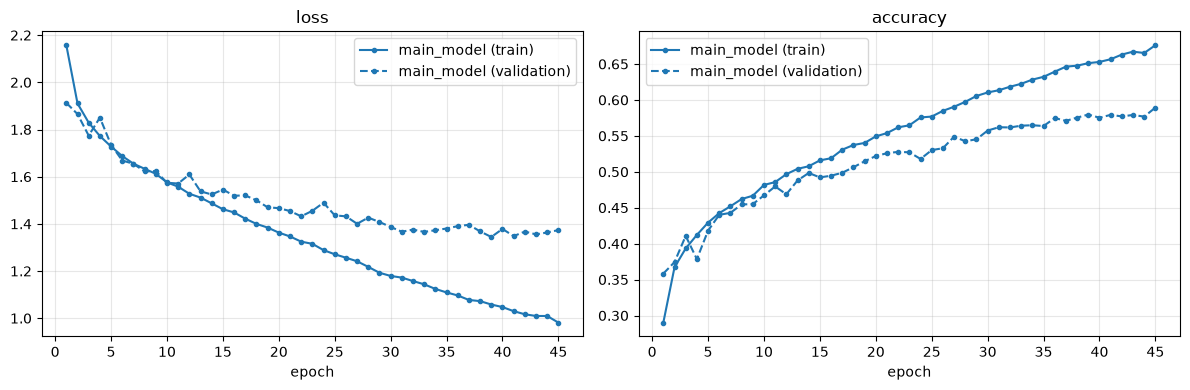

In [16]:
plot_history({"main_model":history}, metrics=('loss', 'accuracy'))

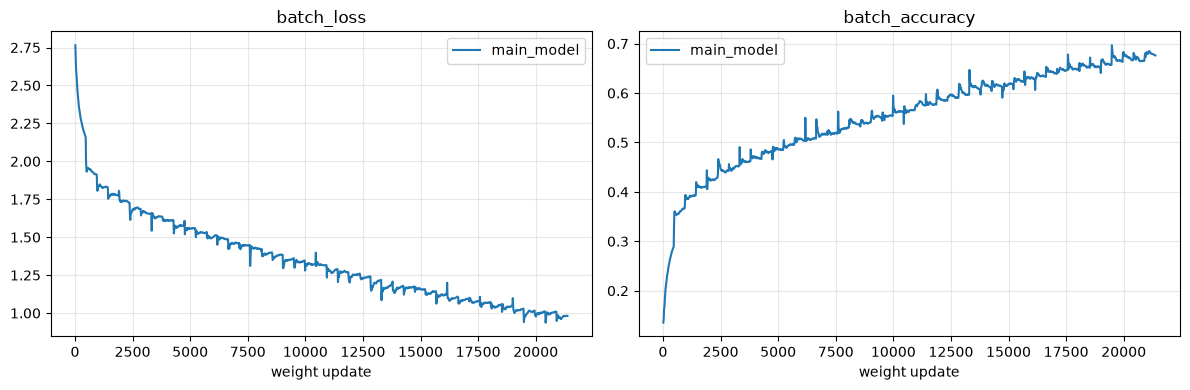

In [17]:
plot_history({"main_model":history}, metrics=('batch_loss', 'batch_accuracy'))

In [18]:
torch.save(myModel.state_dict(), "./eerste_model.pt")


In [10]:

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix, classification_report
def generate_report(model,dataloader,class_names,dataset_name):
    # Model in evaluatiemodus
    model.eval()

    y_true = []
    y_pred = []

    # Geen gradients berekenen tijdens testen
    with torch.no_grad():
        for spectrograms, images, labels in dataloader:

            spectrograms = spectrograms.to(device)
            images = images.to(device)
            labels = labels.to(device)

            # Voorspellingen
            outputs = model(spectrograms,images)

            # Klasse met hoogste score
            predictions = torch.argmax(outputs, dim=1)

            # Resultaten opslaan
            y_true.extend(labels.cpu().numpy())
            y_pred.extend(predictions.cpu().numpy())
    cm = confusion_matrix(y_true, y_pred)


    plt.figure(figsize=(10, 8))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names
    )

    plt.xlabel("Predicted label")
    plt.ylabel("True label")
    plt.title(f"Confusion Matrix - {dataset_name}")

    plt.tight_layout()
    plt.show()

    print(classification_report(
        y_true,
        y_pred,
        target_names=class_names
    ))

In [ ]:
generate_report(myModel,train_dl,id_to_class)
generate_report(myModel,test_dl,id_to_class)
generate_report(myModel,val_dl,id_to_class)

NameError: name 'generate_report' is not defined

# finetuning

In [11]:

from PIL import Image
from torchvision import transforms
from torch.utils.data import Dataset
import torch
import os
from torch.utils.data import random_split, DataLoader
images_path = "/media/plofski/Windows/deepl/images/covers"
audio_path = "/media/plofski/Windows/deepl/audio/samples"
cache_path = "/media/plofski/Windows/deepl/audio/cache"

class SoundFineTuneDS(Dataset):

    def __init__(self, df, images_path, audio_path, cache_path=None):

        self.df = df
        self.images_path = str(images_path)
        self.audio_path = str(audio_path)

        self.duration = 4000
        self.sr = 24000
        self.channel = 1

        self.image_transform = transforms.Compose([
            transforms.Resize((224, 224)),
            transforms.ToTensor()
        ])

        self.image_cache = {}

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.row(idx, named=True)

        track_id = str(row["track_id"])
        album_id = str(row["album_id"])
        class_id = row["genre_id"]

        # Load MP3 directly
        audio_file = os.path.join(
            self.audio_path,
            track_id + ".mp3"
        )

        aud = AudioUtil.open(audio_file)

        # Resample to 24 kHz
        reaud = AudioUtil.resample(aud, self.sr)

        # Convert to mono
        rechan = AudioUtil.rechannel(reaud, self.channel)

        dur_aud = AudioUtil.pad_trunc(
            rechan,
            self.duration
        )

        # Extract audio from tuple if necessary
        if isinstance(dur_aud, tuple):
            dur_aud = dur_aud[0]

        waveform = dur_aud.squeeze(0).float()

        # Load album cover
        if album_id not in self.image_cache:

            image_file = os.path.join(
                self.images_path,
                album_id + ".jpg"
            )

            with Image.open(image_file) as img:
                image = self.image_transform(
                    img.convert("RGB")
                )

            self.image_cache[album_id] = image

        return waveform, class_id


myds_finetuning = SoundFineTuneDS(
    df,
    images_path,
    audio_path,
    cache_path
)


# 70/15/15 split
num_items = len(myds_finetuning)

num_train = int(num_items * 0.70)
num_val = int(num_items * 0.15)
num_test = num_items - num_train - num_val

train_ds_finetuning, val_ds_finetuning, test_ds_finetuning = random_split(
    myds_finetuning,
    [num_train, num_val, num_test],
    generator=torch.Generator().manual_seed(42)
)

# DataLoaders
train_dl_finetuning = DataLoader(
    train_ds_finetuning,
    batch_size=32,
        shuffle=True,
    num_workers=0,
    pin_memory=False,
    persistent_workers=False,
    #prefetch_factor=2

)

val_dl_finetuning = DataLoader(
    val_ds_finetuning,
    batch_size=16,
    shuffle=False,
)

test_dl_finetuning = DataLoader(
    test_ds_finetuning,
    batch_size=16,
        shuffle=True,
    num_workers=1,
    pin_memory=False,
    persistent_workers=False,
    prefetch_factor=1

)


print(f"Training samples: {len(train_ds_finetuning)}")
print(f"Validation samples: {len(val_ds_finetuning)}")
print(f"Testing samples: {len(test_ds_finetuning)}")

Training samples: 30360
Validation samples: 6505
Testing samples: 6507


In [12]:
import torch
from torch import nn
from transformers import AutoModel, Wav2Vec2FeatureExtractor
class MERTClassifier(nn.Module):
    def __init__(self, num_classes):
        super().__init__()

        # Load MERT encoder
        self.encoder = AutoModel.from_pretrained(
            "m-a-p/MERT-v1-95M",
            trust_remote_code=True,
            torch_dtype=torch.float32
        )

        # Freeze volledige MERT encoder
        for param in self.encoder.parameters():
            param.requires_grad = False

        # Classifier blijft trainbaar
        self.classifier = nn.Sequential(
            nn.Linear(768, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, num_classes)
        )

    def train(self, mode=True):
        super().train(mode)

        # Zorg dat MERT altijd in eval mode blijft
        self.encoder.eval()

        return self

    def forward(self, input_values, attention_mask=None):

        # Geen gradients berekenen voor MERT
        with torch.no_grad():
            outputs = self.encoder(
                input_values=input_values,
                attention_mask=attention_mask
            )

            hidden = outputs.last_hidden_state

            # Mean pooling
            pooled = hidden.mean(dim=1)

        # Alleen classifier trainen
        logits = self.classifier(pooled)

        return logits

In [14]:
# Create the model and put it on the GPU if available

overfitting_MERTModel = MERTClassifier(num_classes=n_targets)
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
overfitting_MERTModel = overfitting_MERTModel.to(device)
# Check that it is on Cuda
next(overfitting_MERTModel.parameters()).device

from torch.utils.data import Subset, DataLoader

# Neem 10% van de trainingsdata
dataset = train_ds_finetuning.dataset
n = int(0.1 * len(dataset))

indices = torch.randperm(len(dataset))[:n].tolist()

small_train_dataset = Subset(dataset, indices)

small_train_dl = DataLoader(
    small_train_dataset,
    batch_size=64,
    shuffle=True
)

loss_fn = torch.nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(
    overfitting_MERTModel.parameters(),
    lr=0.001
)

scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=5, gamma=0.1)
history=fit(overfitting_MERTModel, small_train_dl, optimizer, loss_fn, 1, val_loader=None,
        log_every=30, scheduler=None, patience=None)

Epoch 1/1:  54%|█████▍    | 37/68 [13:17<11:07, 21.54s/it, accuracy=0.1524, loss=2.6848, lr=1.00e-03]


KeyboardInterrupt: 

In [21]:
# Create the model and put it on the GPU if available
finetuningModel = MERTClassifier(n_targets)
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
finetuningModel = finetuningModel.to(device)
# Check that it is on Cuda
next(finetuningModel.parameters()).device

loss_fn = torch.nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(
    finetuningModel.parameters(),
    lr=0.001
)

scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=5, gamma=0.1)
history=fit(finetuningModel, train_dl_finetuning, optimizer, loss_fn, 60, val_loader=val_dl_finetuning,
        log_every=15, scheduler=None, patience=6)

Loading weights: 100%|██████████| 211/211 [00:00<00:00, 33422.64it/s]
[transformers] `use_return_dict` is deprecated! Use `return_dict` instead!


RuntimeError: Expected 2D (unbatched) or 3D (batched) input to conv1d, but got input of size: [64, 1, 2, 64, 344]

In [ ]:
generate_report(finetuningModel,train_dl_finetuning,id_to_class)
generate_report(finetuningModel,test_dl_finetuning,id_to_class)
generate_report(finetuningModel,val_dl_finetuning,id_to_class)